In [3]:
import requests
import pandas as pd

dataset_code = "earn_gr_gpgr2"

print("Dataset:", dataset_code)
print("Ready to connect to Eurostat")

Dataset: earn_gr_gpgr2
Ready to connect to Eurostat


In [4]:
import requests
import pandas as pd

dataset_code = "earn_gr_gpgr2"

url = (
    "https://ec.europa.eu/eurostat/api/"
    "dissemination/statistics/1.0/data/"
    f"{dataset_code}"
)

response = requests.get(
    url,
    params={"lang": "EN"},
    timeout=60
)

response.raise_for_status()

data = response.json()

print("Dataset:", data["label"])
print("Last updated:", data.get("updated"))
print("Dimensions:", data["id"])

Dataset: Gender pay gap in unadjusted form by NACE Rev. 2 activity - structure of earnings survey methodology
Last updated: 2026-10-27T23:00:00+0100
Dimensions: ['freq', 'unit', 'nace_r2', 'geo', 'time']


In [5]:
# Inspect the available categories in each dimension

for dimension in data["id"]:
    categories = data["dimension"][dimension]["category"]["index"]

    print(f"\n{dimension.upper()}")
    print("-" * 40)

    # Display the first 20 categories
    for code, position in list(categories.items())[:20]:
        label = data["dimension"][dimension]["category"]["label"].get(code, code)
        print(f"{code}: {label}")

    print("Total categories:", len(categories))


FREQ
----------------------------------------
A: Annual
Total categories: 1

UNIT
----------------------------------------
PC: Percentage
Total categories: 1

NACE_R2
----------------------------------------
B-S: Industry, construction and services (except activities of households as employers and extra-territorial organisations and bodies)
B-S_X_O: Industry, construction and services (except public administration, defense, compulsory social security)
B-N: Business economy
B: Mining and quarrying
C: Manufacturing
D: Electricity, gas, steam and air conditioning supply
E: Water supply; sewerage, waste management and remediation activities
F: Construction
G: Wholesale and retail trade; repair of motor vehicles and motorcycles
H: Transportation and storage
I: Accommodation and food service activities
J: Information and communication
K: Financial and insurance activities
L: Real estate activities
M: Professional, scientific and technical activities
N: Administrative and support service act

In [6]:
# Inspect country codes
print("AVAILABLE COUNTRIES")
print("-" * 40)

geo = data["dimension"]["geo"]["category"]

for code, label in geo["label"].items():
    print(f"{code}: {label}")

# Inspect all industry categories
print("\nAVAILABLE INDUSTRIES")
print("-" * 40)

industry = data["dimension"]["nace_r2"]["category"]

for code, label in industry["label"].items():
    print(f"{code}: {label}")

# Inspect available years
print("\nAVAILABLE YEARS")
print("-" * 40)

years = data["dimension"]["time"]["category"]["index"]

print(list(years.keys()))

AVAILABLE COUNTRIES
----------------------------------------
EU27_2020: European Union - 27 countries (from 2020)
EU28: European Union - 28 countries (2013-2020)
EA21: Euro area – 21 countries (from 2026)
EA20: Euro area – 20 countries (2023-2025)
EA19: Euro area - 19 countries  (2015-2022)
BE: Belgium
BG: Bulgaria
CZ: Czechia
DK: Denmark
DE: Germany
EE: Estonia
IE: Ireland
EL: Greece
ES: Spain
FR: France
HR: Croatia
IT: Italy
CY: Cyprus
LV: Latvia
LT: Lithuania
LU: Luxembourg
HU: Hungary
MT: Malta
NL: Netherlands
AT: Austria
PL: Poland
PT: Portugal
RO: Romania
SI: Slovenia
SK: Slovakia
FI: Finland
SE: Sweden
IS: Iceland
NO: Norway
CH: Switzerland
UK: United Kingdom
ME: Montenegro
MK: North Macedonia
AL: Albania
RS: Serbia
TR: Türkiye

AVAILABLE INDUSTRIES
----------------------------------------
B-S: Industry, construction and services (except activities of households as employers and extra-territorial organisations and bodies)
B-S_X_O: Industry, construction and services (except publ

In [7]:
# Retrieve Germany's gender pay gap data from Eurostat

params = {
    "lang": "EN",
    "freq": "A",
    "unit": "PC",
    "geo": "DE",
    "sinceTimePeriod": "2007",
    "untilTimePeriod": "2024"
}

api_response = requests.get(
    url,
    params=params,
    timeout=60
)

api_response.raise_for_status()

api_data = api_response.json()

print("Dataset:", api_data["label"])
print("Dimensions:", api_data["id"])
print("Dimension sizes:", api_data["size"])
print("Number of observations:", len(api_data.get("value", {})))

Dataset: Gender pay gap in unadjusted form by NACE Rev. 2 activity - structure of earnings survey methodology
Dimensions: ['freq', 'unit', 'nace_r2', 'geo', 'time']
Dimension sizes: [1, 1, 21, 1, 18]
Number of observations: 372


In [8]:
import itertools
import pandas as pd

# Get dimension information
dimensions = api_data["id"]
sizes = api_data["size"]
dimension_info = api_data["dimension"]

records = []

# Convert each observation into a readable row
for observation_index, value in api_data["value"].items():

    index = int(observation_index)
    positions = []

    # Decode the observation's position across dimensions
    for i, size in enumerate(sizes):
        stride = 1
        for following_size in sizes[i + 1:]:
            stride *= following_size

        position = (index // stride) % size
        positions.append(position)

    record = {}

    # Retrieve category codes and readable labels
    for dimension, position in zip(dimensions, positions):

        category = dimension_info[dimension]["category"]
        category_index = category["index"]

        code = next(
            code for code, pos in category_index.items()
            if pos == position
        )

        label = category["label"].get(code, code)

        record[dimension] = label

    record["gender_pay_gap_percent"] = value

    records.append(record)

# Create DataFrame
df = pd.DataFrame(records)

# Rename columns for readability
df = df.rename(columns={
    "freq": "frequency",
    "unit": "unit",
    "nace_r2": "industry",
    "geo": "country",
    "time": "year"
})

# Display the result
print("Dataset shape:", df.shape)
display(df.head(10))

Dataset shape: (372, 6)


,frequency,unit,industry,country,year,gender_pay_gap_percent
0,Annual,Percentage,Mining and quarrying,Germany,2007,5.1
1,Annual,Percentage,Mining and quarrying,Germany,2008,6.8
2,Annual,Percentage,Mining and quarrying,Germany,2009,10.5
3,Annual,Percentage,Mining and quarrying,Germany,2010,12.3
4,Annual,Percentage,Mining and quarrying,Germany,2011,9.8
5,Annual,Percentage,Mining and quarrying,Germany,2012,7.0
6,Annual,Percentage,Mining and quarrying,Germany,2013,4.1
7,Annual,Percentage,Mining and quarrying,Germany,2014,0.4
8,Annual,Percentage,Mining and quarrying,Germany,2015,1.4
9,Annual,Percentage,Mining and quarrying,Germany,2016,2.4


In [9]:
# 1. Check data types
print("DATA TYPES")
print(df.dtypes)

# 2. Check missing values
print("\nMISSING VALUES")
print(df.isnull().sum())

# 3. Check duplicate records
print("\nDUPLICATES")
print("Duplicate rows:", df.duplicated(
    subset=["industry", "year"]
).sum())

# 4. Check missing industry-year combinations
expected = pd.MultiIndex.from_product(
    [df["industry"].unique(), sorted(df["year"].unique())],
    names=["industry", "year"]
)

actual = pd.MultiIndex.from_frame(df[["industry", "year"]])

missing_combinations = expected.difference(actual)

print("\nMISSING INDUSTRY-YEAR COMBINATIONS")
print("Number missing:", len(missing_combinations))
print(missing_combinations.tolist())

# 5. Summary statistics
print("\nSUMMARY STATISTICS")
display(df["gender_pay_gap_percent"].describe())

DATA TYPES
frequency                     str
unit                          str
industry                      str
country                       str
year                          str
gender_pay_gap_percent    float64
dtype: object

MISSING VALUES
frequency                 0
unit                      0
industry                  0
country                   0
year                      0
gender_pay_gap_percent    0
dtype: int64

DUPLICATES
Duplicate rows: 0

MISSING INDUSTRY-YEAR COMBINATIONS
Number missing: 6
[('Industry, construction and services (except activities of households as employers and extra-territorial organisations and bodies)', '2007'), ('Industry, construction and services (except activities of households as employers and extra-territorial organisations and bodies)', '2008'), ('Industry, construction and services (except activities of households as employers and extra-territorial organisations and bodies)', '2009'), ('Public administration and defence; compulsory social secur

count    372.000000
mean      17.623387
std        8.412490
min       -2.200000
25%       10.675000
50%       19.450000
75%       24.425000
max       34.200000
Name: gender_pay_gap_percent, dtype: float64

In [10]:
# Convert year from string to integer
df["year"] = pd.to_numeric(df["year"])

# Check the updated data types
print(df.dtypes)

# Industry ranking for 2024
industry_2024 = (
    df[df["year"] == 2024]
    [["industry", "gender_pay_gap_percent"]]
    .sort_values(
        by="gender_pay_gap_percent",
        ascending=False
    )
    .reset_index(drop=True)
)

print("\nGENDER PAY GAP BY INDUSTRY IN 2024")
display(industry_2024)

frequency                     str
unit                          str
industry                      str
country                       str
year                        int64
gender_pay_gap_percent    float64
dtype: object

GENDER PAY GAP BY INDUSTRY IN 2024


,industry,gender_pay_gap_percent
0,Financial and insurance activities,26.0
1,"Professional, scientific and technical activities",25.2
2,"Arts, entertainment and recreation",20.6
3,Wholesale and retail trade; repair of motor ve...,19.3
4,Information and communication,19.3
5,Business economy,19.1
6,Manufacturing,19.1
7,Human health and social work activities,18.7
8,"Industry, construction and services (except pu...",15.6
9,"Industry, construction and services (except ac...",14.8


In [11]:
# Compare industry values in 2007 and 2024

comparison = df[df["year"].isin([2007, 2024])]

comparison = comparison.pivot(
    index="industry",
    columns="year",
    values="gender_pay_gap_percent"
).reset_index()

comparison["change_percentage_points"] = (
    comparison[2024] - comparison[2007]
)

comparison = comparison.sort_values(
    by="change_percentage_points"
)

display(comparison)

year,industry,2007,2024,change_percentage_points
14,Other service activities,26.3,13.8,-12.5
19,"Water supply; sewerage, waste management and r...",8.3,-2.2,-10.5
12,Manufacturing,28.9,19.1,-9.8
11,Information and communication,28.9,19.3,-9.6
15,"Professional, scientific and technical activities",34.2,25.2,-9.0
6,"Electricity, gas, steam and air conditioning s...",21.5,13.8,-7.7
0,Accommodation and food service activities,13.7,6.2,-7.5
17,Real estate activities,19.6,12.2,-7.4
10,"Industry, construction and services (except pu...",22.8,15.6,-7.2
2,"Arts, entertainment and recreation",27.7,20.6,-7.1


In [12]:
# Identify broad industry aggregates
aggregates = [
    "Industry, construction and services (except activities of households as employers and extra-territorial organisations and bodies)",
    "Industry, construction and services (except public administration, defense, compulsory social security)",
    "Business economy"
]

# Keep individual industries only
industry_data = df[
    ~df["industry"].isin(aggregates)
].copy()

# Rank individual industries in 2024
industry_2024_clean = (
    industry_data[industry_data["year"] == 2024]
    [["industry", "gender_pay_gap_percent"]]
    .sort_values(
        "gender_pay_gap_percent",
        ascending=False
    )
    .reset_index(drop=True)
)

display(industry_2024_clean)

,industry,gender_pay_gap_percent
0,Financial and insurance activities,26.0
1,"Professional, scientific and technical activities",25.2
2,"Arts, entertainment and recreation",20.6
3,Information and communication,19.3
4,Wholesale and retail trade; repair of motor ve...,19.3
5,Manufacturing,19.1
6,Human health and social work activities,18.7
7,Other service activities,13.8
8,"Electricity, gas, steam and air conditioning s...",13.8
9,Administrative and support service activities,13.3


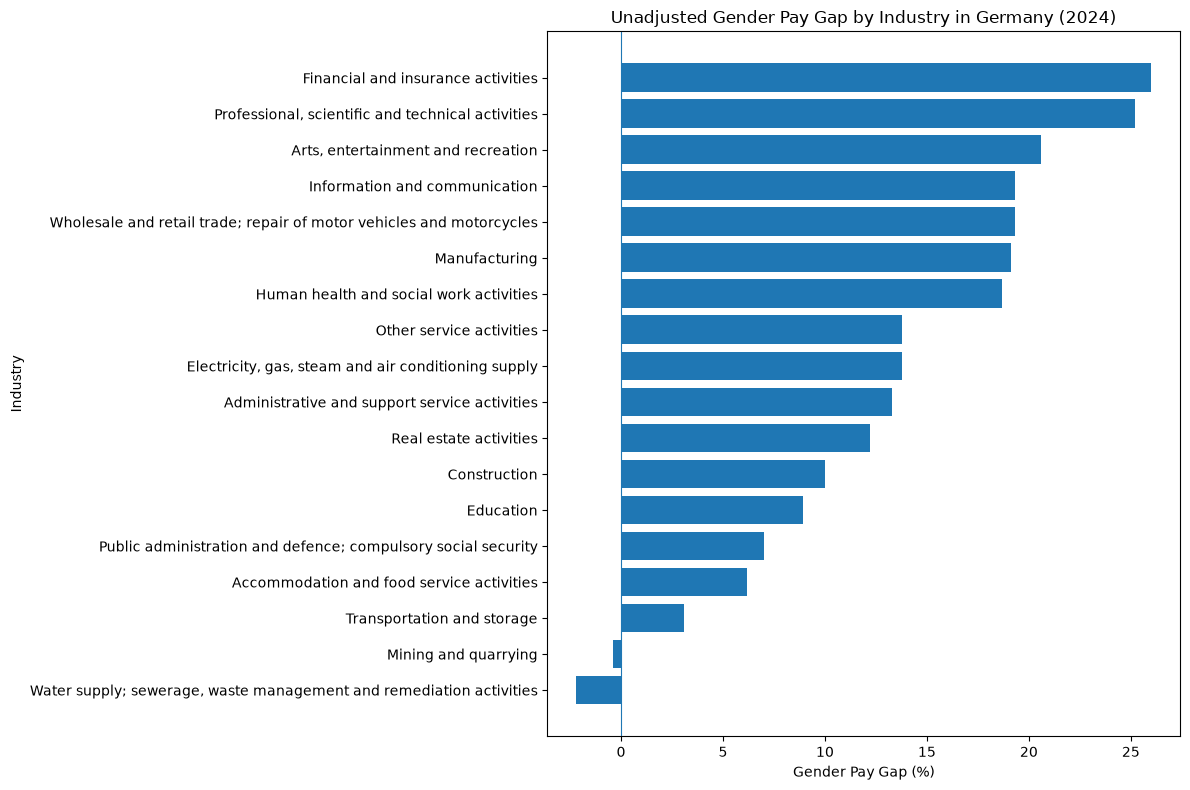

In [13]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 8))

plt.barh(
    industry_2024_clean["industry"],
    industry_2024_clean["gender_pay_gap_percent"]
)

plt.axvline(0, linewidth=0.8)

plt.xlabel("Gender Pay Gap (%)")
plt.ylabel("Industry")
plt.title(
    "Unadjusted Gender Pay Gap by Industry in Germany (2024)"
)

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [14]:
# Calculate the average gender pay gap across individual industries per year

yearly_trend = (
    industry_data
    .groupby("year")
    .agg(
        average_gap=("gender_pay_gap_percent", "mean"),
        median_gap=("gender_pay_gap_percent", "median"),
        industries_covered=("industry", "count")
    )
    .reset_index()
)

print("GENDER PAY GAP TREND: 2007–2024")
display(yearly_trend.round(2))

GENDER PAY GAP TREND: 2007–2024


,year,average_gap,median_gap,industries_covered
0,2007,20.15,21.50,17
1,2008,20.12,21.40,17
2,2009,19.95,21.50,17
3,2010,18.86,20.95,18
4,2011,18.77,19.60,18
5,2012,18.48,19.25,18
6,2013,17.96,19.35,18
7,2014,17.86,18.75,18
8,2015,17.29,17.45,18
9,2016,16.81,17.80,18


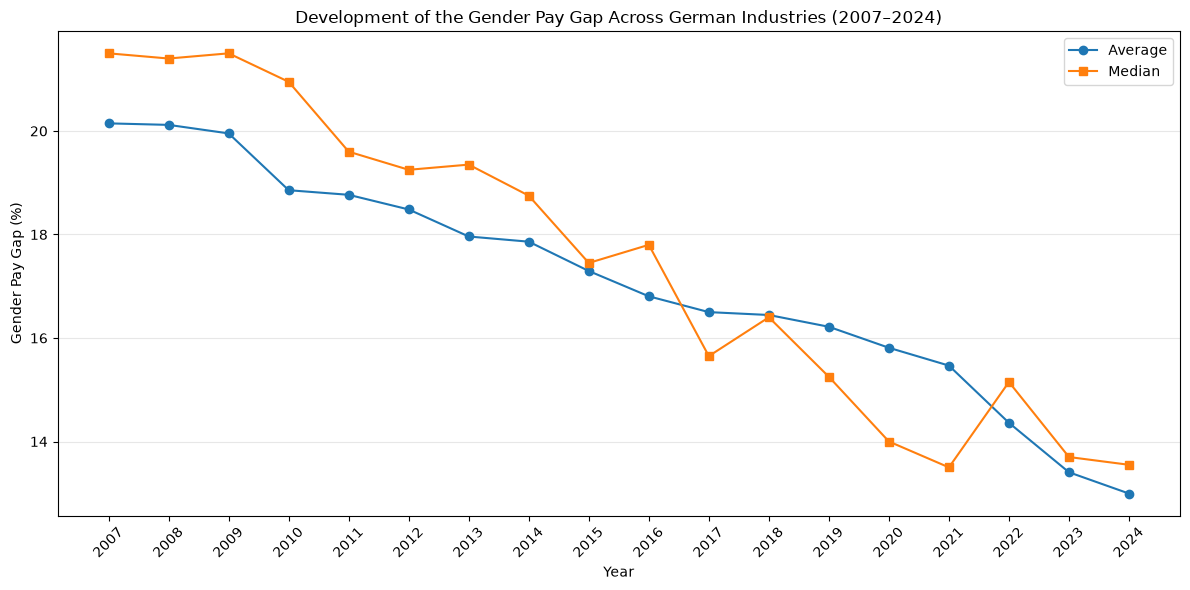

In [15]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.plot(
    yearly_trend["year"],
    yearly_trend["average_gap"],
    marker="o",
    label="Average"
)

plt.plot(
    yearly_trend["year"],
    yearly_trend["median_gap"],
    marker="s",
    label="Median"
)

plt.title(
    "Development of the Gender Pay Gap Across German Industries (2007–2024)"
)

plt.xlabel("Year")
plt.ylabel("Gender Pay Gap (%)")
plt.xticks(yearly_trend["year"], rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

In [16]:
first_year = yearly_trend.iloc[0]
last_year = yearly_trend.iloc[-1]

change = last_year["average_gap"] - first_year["average_gap"]

print("HISTORICAL COMPARISON")
print("------------------------------")
print(f"Average gap in 2007: {first_year['average_gap']:.2f}%")
print(f"Average gap in 2024: {last_year['average_gap']:.2f}%")
print(f"Change: {change:.2f} percentage points")

HISTORICAL COMPARISON
------------------------------
Average gap in 2007: 20.15%
Average gap in 2024: 12.99%
Change: -7.15 percentage points


## Export Data for PostgreSQL

I will export my cleaned Eurostat dataset to CSV so that I can load it into PostgreSQL from my second notebook.

In [17]:
# Import Path to manage project folders and file paths
from pathlib import Path

# Create the data folder if it does not already exist
data_folder = Path("data")
data_folder.mkdir(exist_ok=True)

# Export my Eurostat DataFrame as a CSV file
df.to_csv(data_folder / "eurostat_gender_pay_gap.csv", index=False)

# Confirm the exported file location
print("Dataset exported successfully!")
print("File location:", data_folder / "eurostat_gender_pay_gap.csv")
print("Number of observations:", len(df))

Dataset exported successfully!
File location: data/eurostat_gender_pay_gap.csv
Number of observations: 372
